# 02 Exploratory market analysis

| Field | Value |
|---|---|
| **Purpose** | Understand the job market before modelling: pay, geography, timing, title words, and whether jobs that state pay differ from those that do not |
| **Assignment requirement** | Tasks 1-8: exploratory evidence that later notebooks test (salary, categories, demand, country rates, forecasting, recommendations) |
| **Inputs** | `jobs_clean.parquet`, `eligibility_counts.csv` |
| **Outputs** | None; findings and testable hypotheses for Notebooks 03-07 |
| **Build identity** | Printed by the first code cell |

**EDA** (exploratory data analysis) means studying the data with summaries and charts to find patterns. EDA *suggests*; it does not *prove*. That is why this notebook ends with a list of **hypotheses**: statements that later notebooks test properly.

**How to read this notebook**

- Every analysis uses one of the populations defined in Notebook 01 through its eligibility flag. A *population* is the exact set of rows allowed for one kind of question, for example "hourly jobs with a complete rate range".
- **Hourly rates and fixed-price budgets are never mixed or compared.** One is money per hour, the other is a total amount for a whole job.
- Each section ends with **Finding → Evidence → What a later notebook must test**.
- Section 8 checks every number quoted in the text against the data.

In [1]:
from job_market.notebook import start

project = start()

RUN_ID: 20261004T070541Z-0dd674f883
Source: data/raw/all_upwork_jobs_2024-02-07-2024-03-24.csv (244,828 rows)
Taxonomy version: 1.0
Verified outputs: 12 file(s), all hashes match
Environment: matches environment.yml


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from job_market.stats import cramers_v
from job_market.text import STOP_WORDS, count_ngrams, tokenize, top_ngrams

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

# Only the columns this notebook needs: the full table is large.
columns = [
    "row_id", "title_key", "title_word_count", "title_script", "country", "posted_date", "weekday", "hour",
    "contract_type", "pay_info", "hourly_mid", "budget", "valid_job_record",
    "eligible_for_text_analysis", "eligible_for_hourly_rate_analysis", "eligible_for_budget_analysis",
    "eligible_for_timeseries", "extreme_hourly_rate_flag", "extreme_budget_flag", "possible_repost_3d", "day_status",
]
jobs = project.read_parquet("jobs_clean.parquet", columns=columns)
eligibility = project.read_csv("eligibility_counts.csv").set_index("flag")
# Plain text instead of a category, so tables line up the same way in every pandas version.
jobs["weekday"] = jobs["weekday"].astype(str)

valid = jobs["valid_job_record"]
hourly_pay = jobs[jobs["eligible_for_hourly_rate_analysis"]]
budget_pay = jobs[jobs["eligible_for_budget_analysis"]]
time_jobs = jobs[jobs["eligible_for_timeseries"]]
text_jobs = jobs[jobs["eligible_for_text_analysis"]]
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Chart style shared with Notebook 01.
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "legend.frameon": False,
})
print(f"Loaded {len(jobs):,} rows x {len(columns)} columns")

Loaded 244,828 rows x 21 columns


## 1. Market at a glance

How many rows each population has, and how the market splits by contract type.

In [3]:
populations = pd.DataFrame({
    "population": ["all valid jobs", "titles (text analysis)", "hourly pay (complete rate range)",
                   "fixed-price budgets", "daily counts (time-series window)"],
    "flag": ["valid_job_record", "eligible_for_text_analysis", "eligible_for_hourly_rate_analysis",
             "eligible_for_budget_analysis", "eligible_for_timeseries"],
})
populations["rows"] = populations["flag"].map(eligibility["rows"])
populations["share_of_all_pct"] = populations["flag"].map(eligibility["share_of_all_rows_pct"])
populations

,population,flag,rows,share_of_all_pct
0,all valid jobs,valid_job_record,244827,100.00
1,titles (text analysis),eligible_for_text_analysis,244827,100.00
2,hourly pay (complete rate range),eligible_for_hourly_rate_analysis,98775,40.34
3,fixed-price budgets,eligible_for_budget_analysis,103891,42.43
4,daily counts (time-series window),eligible_for_timeseries,229520,93.75


In [4]:
mix = (jobs.loc[valid, "pay_info"].value_counts().rename("jobs").to_frame()
           .assign(share_pct=lambda t: (100 * t["jobs"] / t["jobs"].sum()).round(1)))
mix

,jobs,share_pct
pay_info,,
fixed_budget,103891,42.4
hourly_range,98775,40.3
hourly_no_rate,38514,15.7
hourly_low_only,3647,1.5


**Finding** → About 58% of jobs are hourly and 42% fixed-price. Every fixed-price job states a budget, but more than a quarter of hourly jobs state no rate at all.

**Evidence** → The two tables above.

**What a later notebook must test** → NB04 (salary) can use about 99,000 hourly jobs and about 104,000 fixed-price jobs, as two separate analyses. Whether the hourly jobs *without* a rate differ from those *with* one is checked in section 4.

## 2. One variable at a time

### 2.1 Pay: hourly rates and fixed budgets, separately

Two terms used below:

- **Skewness** measures how much a distribution leans to one side. Large positive skewness means a long tail of high values.
- **Kurtosis** measures how heavy the tails are compared with a normal bell curve. High kurtosis means rare extreme values are common enough to pull the mean.

With long tails, the **median** (the middle value) is the honest summary: a few huge values cannot move it much. The **IQR** (interquartile range, the 25th to 75th percentile) shows where the middle half of jobs sits. The charts use a **log scale**, where each step on the axis is ten times the previous one, so both typical and extreme values are visible. The stored data is not transformed.

In [5]:
def pay_summary(frame, column, flag):
    rows = {}
    for label, part in [("all eligible jobs", frame), ("without flagged extremes", frame[~frame[flag]])]:
        values = part[column]
        rows[label] = {
            "jobs": len(values), "mean": values.mean(), "median": values.median(),
            "p25": values.quantile(0.25), "p75": values.quantile(0.75), "p90": values.quantile(0.90),
            "p99": values.quantile(0.99), "skewness": values.skew(), "kurtosis": values.kurt(),
        }
    return pd.DataFrame(rows).T

hourly_summary = pay_summary(hourly_pay, "hourly_mid", "extreme_hourly_rate_flag")
budget_summary = pay_summary(budget_pay, "budget", "extreme_budget_flag")
print("Hourly rate (USD per hour, midpoint of the stated range):")
display(hourly_summary.round(2))
print("Fixed-price budget (USD per job):")
display(budget_summary.round(2))

Hourly rate (USD per hour, midpoint of the stated range):


,jobs,mean,median,p25,p75,p90,p99,skewness,kurtosis
all eligible jobs,98775.0,29.71,22.5,14.0,35.0,57.0,135.0,6.51,84.14
without flagged extremes,98502.0,28.77,22.5,14.0,35.0,55.0,122.5,2.94,15.76


Fixed-price budget (USD per job):


,jobs,mean,median,p25,p75,p90,p99,skewness,kurtosis
all eligible jobs,103891.0,911.47,100.0,25.0,300.0,1000.0,10000.0,54.33,3273.10
without flagged extremes,103772.0,548.81,100.0,25.0,300.0,1000.0,8000.0,17.60,415.08


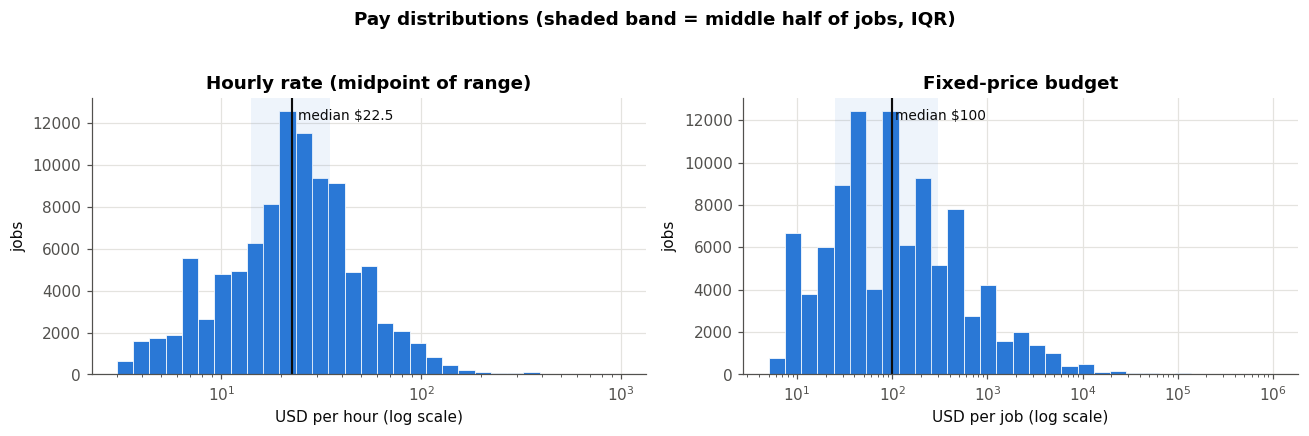

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, values, title, unit in [
    (axes[0], hourly_pay["hourly_mid"], "Hourly rate (midpoint of range)", "USD per hour"),
    (axes[1], budget_pay["budget"], "Fixed-price budget", "USD per job"),
]:
    bins = np.logspace(np.log10(values.min()), np.log10(values.max()), 32)
    ax.hist(values, bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_xscale("log")
    q25, q50, q75 = values.quantile([0.25, 0.5, 0.75])
    ax.axvspan(q25, q75, color=BLUE, alpha=0.08, lw=0)
    ax.axvline(q50, color=INK, lw=1.4)
    ax.text(q50 * 1.08, ax.get_ylim()[1] * 0.92, f"median ${q50:,.4g}", fontsize=9, color=INK)
    ax.set_title(title)
    ax.set_xlabel(f"{unit} (log scale)")
    ax.set_ylabel("jobs")
fig.suptitle("Pay distributions (shaded band = middle half of jobs, IQR)", fontweight="bold", y=1.03)
fig.tight_layout()
plt.show()

**Finding** → The typical hourly job pays **$22.50 per hour** (middle half: $14 to $35). The typical fixed-price job has a **$100 budget** (middle half: $25 to $300). Both have very long right tails: the hourly mean is above the median, and the budget mean is about nine times the median. Removing the flagged extreme values leaves both medians and both IQRs unchanged; it only shrinks the mean, skewness and kurtosis.

**Evidence** → The two summary tables and the histograms.

**What a later notebook must test** → NB04 must model pay with medians or on a log scale, not with raw means, and report results with and without extreme values.

### 2.2 Countries

Country is the location of the client posting the job.

Countries: 212; jobs with a country: 239,751; jobs without a country: 5,076 (not ranked)
Top 10 countries hold 75.4% of jobs with a country; 96 countries have fewer than 30 jobs.


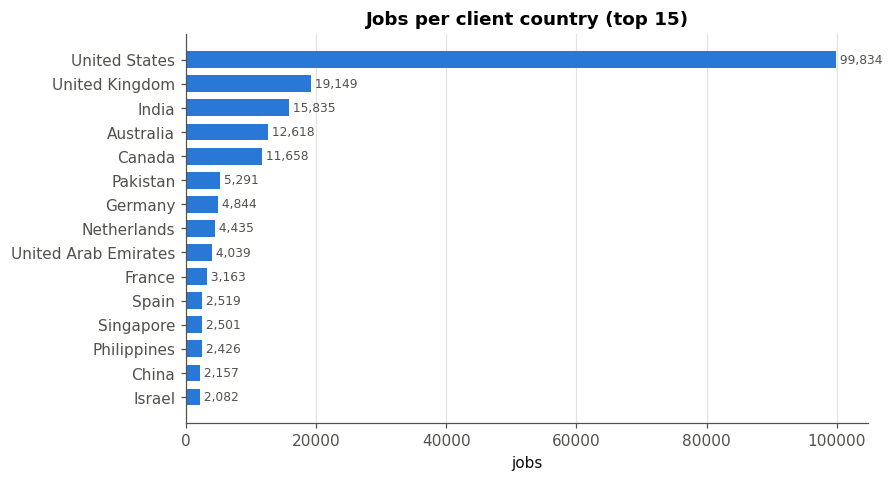

In [7]:
country_counts = jobs.loc[valid, "country"].value_counts()
known = jobs.loc[valid, "country"].notna().sum()
top10_share = 100 * country_counts.head(10).sum() / known
small_countries = int((country_counts < 30).sum())
print(f"Countries: {country_counts.size}; jobs with a country: {known:,}; "
      f"jobs without a country: {int(valid.sum() - known):,} (not ranked)")
print(f"Top 10 countries hold {top10_share:.1f}% of jobs with a country; "
      f"{small_countries} countries have fewer than 30 jobs.")

top15 = country_counts.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top15.index, top15.values, color=BLUE, height=0.7)
for y, value in enumerate(top15.values):
    ax.text(value, y, f" {value:,}", va="center", fontsize=8, color=MUTED)
ax.set_title("Jobs per client country (top 15)")
ax.set_xlabel("jobs")
ax.grid(axis="y", visible=False)
plt.show()

**Finding** → Demand is very concentrated: the United States alone posts about 42% of all jobs with a country, and the top 10 countries about three quarters. Almost half of the 212 countries have fewer than 30 jobs.

**Evidence** → The printed shares and the bar chart.

**What a later notebook must test** → NB04 (Task 4, rates by country) must set a minimum number of jobs before ranking a country, and should report uncertainty, because a country with 30 jobs is far less certain than one with 30,000.

### 2.3 Time: weekdays and hours

The 37-day time-series window contains **6 Fridays and 6 Saturdays but only 5 of every other weekday**. Raw weekly totals would therefore overstate Fridays and Saturdays. The fair measure is the **average number of postings per day** for each weekday. Hours are UTC, not the client's local time.

,days in window,raw total,average per day
weekday,,,
Monday,5,34167,6833.0
Tuesday,5,35132,7026.0
Wednesday,5,35357,7071.0
Thursday,5,34875,6975.0
Friday,6,39254,6542.0
Saturday,6,28429,4738.0
Sunday,5,22306,4461.0


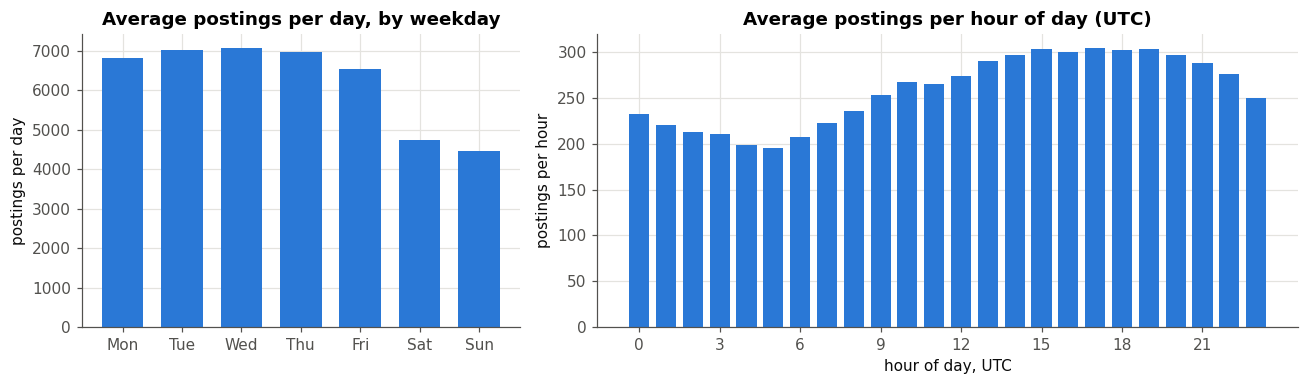

In [8]:
day_weekday = time_jobs.groupby("posted_date", observed=True)["weekday"].first()
days_per_weekday = day_weekday.value_counts().reindex(WEEKDAYS)
per_weekday = (time_jobs["weekday"].value_counts().reindex(WEEKDAYS) / days_per_weekday)
per_hour = time_jobs.groupby("hour").size() / time_jobs["posted_date"].nunique()

weekday_table = pd.DataFrame({
    "days in window": days_per_weekday,
    "raw total": time_jobs["weekday"].value_counts().reindex(WEEKDAYS),
    "average per day": per_weekday.round(0),
})
display(weekday_table)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].bar([d[:3] for d in WEEKDAYS], per_weekday.values, color=BLUE, width=0.7)
axes[0].set_title("Average postings per day, by weekday")
axes[0].set_ylabel("postings per day")
axes[1].bar(per_hour.index, per_hour.values, color=BLUE, width=0.75)
axes[1].set_title("Average postings per hour of day (UTC)")
axes[1].set_xlabel("hour of day, UTC")
axes[1].set_ylabel("postings per hour")
axes[1].set_xticks(range(0, 24, 3))
fig.tight_layout()
plt.show()

**Finding** → Weekdays are busy and weekends quiet: Monday to Thursday each average about 6,800 to 7,100 postings per day, Friday about 6,500, and Saturday and Sunday about 4,500 to 4,700. Postings peak in the UTC afternoon and evening (around 17:00 UTC, which is morning in the Americas) and are lowest around 05:00 UTC.

Note: counted as raw totals, Friday would look like the busiest day, only because the window contains six Fridays. Dividing by the number of days fixes this.

**Evidence** → The weekday table (raw total vs average per day) and the two charts.

**What a later notebook must test** → NB06 (forecasting) must model a weekly pattern (weekday effect), and every daily comparison must use averages per day, not totals.

### 2.4 Titles

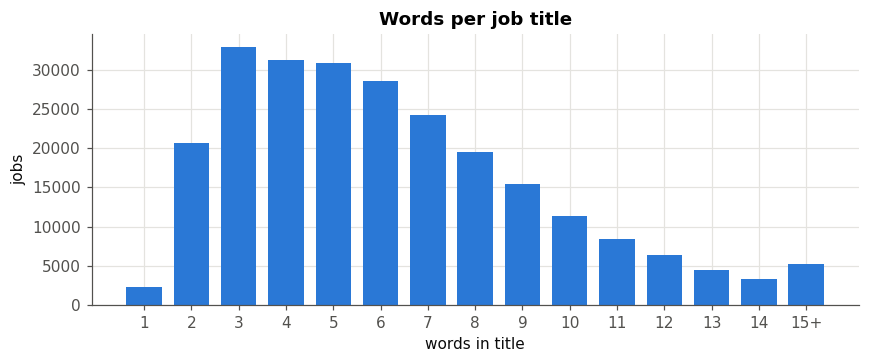

Median title length: 6 words


title_script,latin,cyrillic,mixed,arabic,greek,cjk,devanagari,hebrew,none
titles,244639,87,72,16,6,5,1,1,0


In [9]:
words_dist = text_jobs["title_word_count"].clip(upper=15).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(words_dist.index, words_dist.values, color=BLUE, width=0.75)
ax.set_xticks(range(1, 16))
ax.set_xticklabels([str(i) for i in range(1, 15)] + ["15+"])
ax.set_title("Words per job title")
ax.set_xlabel("words in title")
ax.set_ylabel("jobs")
plt.show()
print(f"Median title length: {text_jobs['title_word_count'].median():.0f} words")
text_jobs["title_script"].value_counts().rename("titles").to_frame().T

**Finding** → Job titles are short: half have 6 words or fewer. Almost all (more than 99.9%) are written in the Latin alphabet, so the alphabet says nothing useful about most jobs. (Latin script does not mean English; see decision D-018.)

**Evidence** → The chart and the script table.

**What a later notebook must test** → NB03 must build categories from very short texts, so it needs methods that work on a handful of words (keyword rules, phrase matching, sentence embeddings), not long-document methods.

## 3. Two variables together

### 3.1 Pay by country

Only countries with **at least 30 pay-eligible jobs** are shown. This is a display rule for this notebook (decision D-020), not a project-wide rule: no rows are removed. The charts show the 20 countries with the most eligible jobs; the dot is the median and the line the IQR.

Countries shown: 91 for hourly rates, 104 for budgets


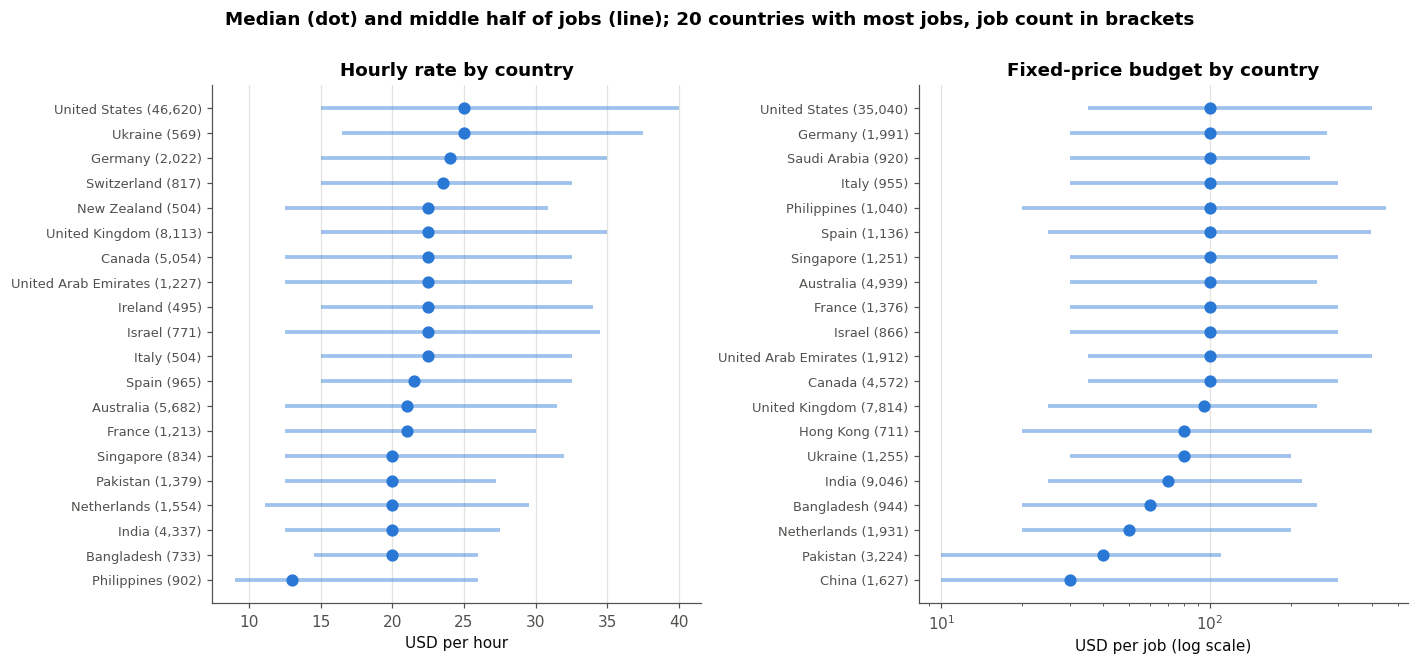

In [10]:
def country_pay(frame, column, min_jobs=30):
    table = (frame.dropna(subset=["country"]).groupby("country", observed=True)[column]
                  .agg(jobs="size", median="median", p25=lambda s: s.quantile(0.25), p75=lambda s: s.quantile(0.75)))
    return table[table["jobs"] >= min_jobs]

hourly_country = country_pay(hourly_pay, "hourly_mid")
budget_country = country_pay(budget_pay, "budget")
print(f"Countries shown: {len(hourly_country)} for hourly rates, {len(budget_country)} for budgets")

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, table, title, unit in [
    (axes[0], hourly_country, "Hourly rate by country", "USD per hour"),
    (axes[1], budget_country, "Fixed-price budget by country", "USD per job (log scale)"),
]:
    top = table.sort_values("jobs", ascending=False).head(20).sort_values("median")
    y = np.arange(len(top))
    ax.hlines(y, top["p25"], top["p75"], color=BLUE, lw=2.5, alpha=0.45)
    ax.plot(top["median"], y, "o", color=BLUE, markersize=7)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{name} ({n:,})" for name, n in zip(top.index, top["jobs"])], fontsize=8.5)
    ax.set_title(title)
    ax.set_xlabel(unit)
    ax.grid(axis="y", visible=False)
    if "log" in unit:
        ax.set_xscale("log")
fig.suptitle("Median (dot) and middle half of jobs (line); 20 countries with most jobs, job count in brackets",
             fontweight="bold", y=1.0)
fig.tight_layout()
plt.show()

In [11]:
print("Hourly rate, the 20 countries with most jobs:")
display(hourly_country.sort_values("jobs", ascending=False).head(20).round(1))
print("Highest median hourly rates among all countries with at least 30 jobs (small samples!):")
hourly_country.sort_values("median", ascending=False).head(8).round(1)

Hourly rate, the 20 countries with most jobs:


,jobs,median,p25,p75
country,,,,
United States,46620,25.0,15.0,40.0
United Kingdom,8113,22.5,15.0,35.0
Australia,5682,21.0,12.5,31.5
Canada,5054,22.5,12.5,32.5
India,4337,20.0,12.5,27.5
Germany,2022,24.0,15.0,35.0
Netherlands,1554,20.0,11.1,29.5
Pakistan,1379,20.0,12.5,27.2
United Arab Emirates,1227,22.5,12.5,32.5


Highest median hourly rates among all countries with at least 30 jobs (small samples!):


,jobs,median,p25,p75
country,,,,
Latvia,106,30.0,20.0,42.5
Oman,49,29.0,19.5,33.5
Vietnam,250,27.5,17.6,28.2
Moldova,40,26.5,10.5,35.5
Kenya,314,26.0,17.5,40.0
Nepal,58,25.0,16.5,27.5
Hungary,148,25.0,14.8,37.5
Kuwait,66,25.0,16.5,34.9


**Finding** → Among the large markets, the median hourly rate ranges from about **$13 (Philippines) to $25 (United States)**. The large English-speaking and Western European markets (UK, Canada, Australia, Ireland, New Zealand, Germany, France, Spain, Italy, Netherlands) sit between $20 and $24. Fixed budgets differ more strongly: the US, UK, Australia and Canada sit around $95 to $100, while India ($70), Pakistan ($40) and China ($30) are much lower. The highest medians overall belong to small countries with a few dozen to a few hundred jobs, so they are less reliable.

**Evidence** → The two charts and tables. The IQR lines overlap heavily for most countries: country explains only part of the pay difference.

**What a later notebook must test** → NB04 (Task 4) must report each country's median with a confidence interval and a sample size, and check whether country differences remain after accounting for job category (an expensive country may simply post more developer jobs).

### 3.2 When jobs are posted: weekday × hour

A **heatmap** shows a value for every combination of two variables as a colour: darker means more postings. Each cell is the average number of postings in that hour on that weekday.

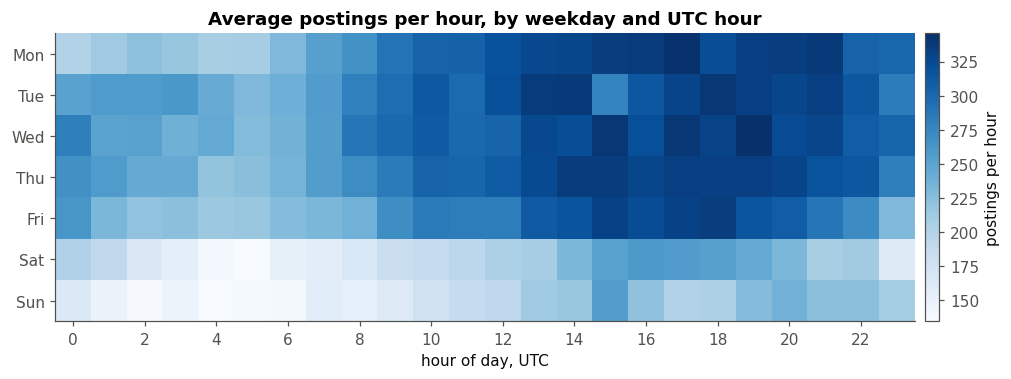

In [12]:
counts = time_jobs.groupby(["weekday", "hour"], observed=True).size().unstack(fill_value=0).reindex(WEEKDAYS)
heat = counts.div(days_per_weekday, axis=0)
fig, ax = plt.subplots(figsize=(12, 3.4))
image = ax.imshow(heat.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(7))
ax.set_yticklabels([d[:3] for d in WEEKDAYS])
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of day, UTC")
ax.set_title("Average postings per hour, by weekday and UTC hour")
ax.grid(False)
fig.colorbar(image, ax=ax, label="postings per hour", pad=0.01)
plt.show()

**Finding** → The weekday and hour patterns combine: weekday afternoons and evenings (UTC) are the busiest, weekend nights the quietest.

**Evidence** → The heatmap.

**What a later notebook must test** → NB06 forecasts daily totals, so it needs the weekday effect; the hour pattern matters only for the dashboard (Task 6), where it can be shown as a market rhythm.

### 3.3 Contract type by country

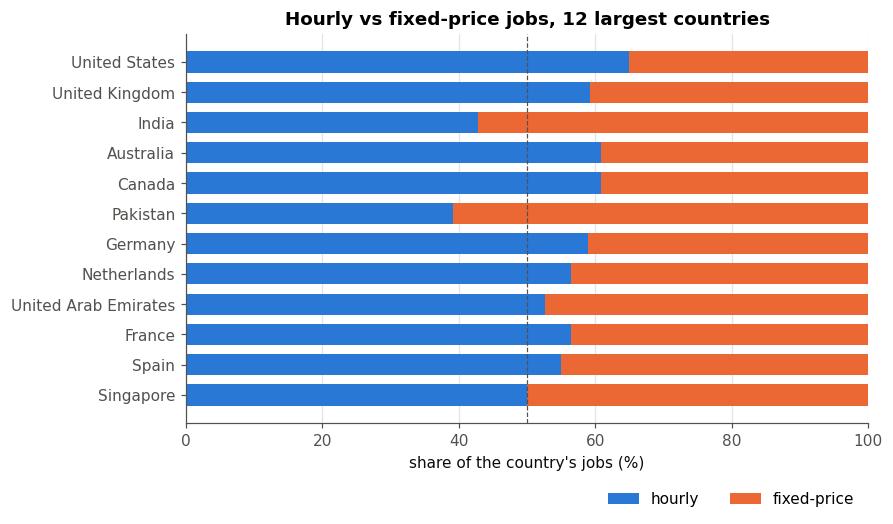

contract_type,fixed,hourly
country,,
United States,35.1,64.9
United Kingdom,40.8,59.2
India,57.1,42.9
Australia,39.1,60.9
Canada,39.2,60.8
Pakistan,60.9,39.1
Germany,41.1,58.9
Netherlands,43.5,56.5
United Arab Emirates,47.3,52.7


In [13]:
top_countries = jobs.loc[valid, "country"].value_counts().head(12).index
contract_mix = (pd.crosstab(jobs.loc[valid & jobs["country"].isin(top_countries), "country"],
                            jobs.loc[valid & jobs["country"].isin(top_countries), "contract_type"], normalize="index")
                  .mul(100).reindex(top_countries[::-1]))
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(contract_mix.index, contract_mix["hourly"], color=BLUE, height=0.7, label="hourly")
ax.barh(contract_mix.index, contract_mix["fixed"], left=contract_mix["hourly"], color=ORANGE, height=0.7, label="fixed-price")
ax.axvline(50, color=MUTED, lw=0.8, ls="--")
ax.set_xlim(0, 100)
ax.set_xlabel("share of the country's jobs (%)")
ax.set_title("Hourly vs fixed-price jobs, 12 largest countries")
ax.legend(loc="lower right", bbox_to_anchor=(1, -0.25), ncol=2)
ax.grid(axis="y", visible=False)
plt.show()
contract_mix.round(1)[::-1]

**Finding** → Clients in the US, UK, Canada, Australia and Western Europe mostly hire **hourly** (about 55-65%), while clients in India and Pakistan mostly post **fixed-price** jobs (about 57-61%).

**Evidence** → The chart and table.

**What a later notebook must test** → Contract type and country are linked, so NB04 must analyse hourly and fixed-price pay separately per country (already the rule), and NB07 (recommender) can offer contract type as a filter.

## 4. Missing-pay check: do hourly jobs that state a rate differ from those that do not?

Task 1 (keywords vs pay) can only use jobs that state pay. If those jobs differ strongly from the others, Task 1's results describe only "jobs that state pay", not the whole market.

- **Hourly jobs:** compare jobs with a complete rate range against jobs with one rate or none.
- **Fixed-price jobs:** every fixed-price job has a budget (Notebook 01), so there is nothing to compare.

With about 141,000 hourly jobs, almost any difference, however tiny, gives a p-value near zero. A *p-value* only says whether a difference could be pure chance, not whether it is large. So this section measures **size**:

- **Difference in shares** in percentage points (pp), for example "47% vs 43% from the US" is a 4 pp difference.
- **Cramér's V**, a 0-to-1 measure of how strongly two categories are linked (0 = not at all). Below 0.1 is usually read as negligible.

In [14]:
hourly_jobs = jobs[valid & jobs["contract_type"].eq("hourly")].copy()
hourly_jobs["rate_group"] = np.where(hourly_jobs["pay_info"].eq("hourly_range"), "states rate", "no/partial rate")
group_sizes = hourly_jobs["rate_group"].value_counts()
display(group_sizes.to_frame("hourly jobs"))

top15_countries = hourly_jobs["country"].value_counts().head(15).index
country_group = hourly_jobs["country"].where(hourly_jobs["country"].isin(top15_countries), "all other countries")
country_group = country_group.fillna("(no country)")
country_table = pd.crosstab(country_group, hourly_jobs["rate_group"])
country_shares = country_table.div(country_table.sum(), axis=1).mul(100)
country_shares["difference_pp"] = country_shares["states rate"] - country_shares["no/partial rate"]

weekday_table_rate = pd.crosstab(hourly_jobs["weekday"], hourly_jobs["rate_group"])
v_country = cramers_v(country_table)
v_weekday = cramers_v(weekday_table_rate)
length = hourly_jobs.groupby("rate_group")["title_word_count"].median()

print(f"Cramér's V, country vs rate stated: {v_country:.3f}")
print(f"Cramér's V, weekday vs rate stated: {v_weekday:.3f}")
print(f"Median title length: {length['states rate']:.0f} words (states rate) vs {length['no/partial rate']:.0f} words (no/partial rate)")
country_shares.sort_values("difference_pp").round(1)

,hourly jobs
rate_group,
states rate,98775
no/partial rate,42161


Cramér's V, country vs rate stated: 0.069
Cramér's V, weekday vs rate stated: 0.007
Median title length: 5 words (states rate) vs 6 words (no/partial rate)


rate_group,no/partial rate,states rate,difference_pp
country,,,
all other countries,19.6,17.5,-2.1
India,5.8,4.4,-1.4
United Arab Emirates,2.1,1.2,-0.9
Netherlands,2.3,1.6,-0.7
Israel,1.1,0.8,-0.3
Pakistan,1.6,1.4,-0.2
Philippines,1.1,0.9,-0.2
Singapore,1.0,0.8,-0.1
France,1.4,1.2,-0.1


Which title words are more common in each group? The share below is the percentage of titles in the group that contain the word (only words that appear in at least 500 hourly titles).

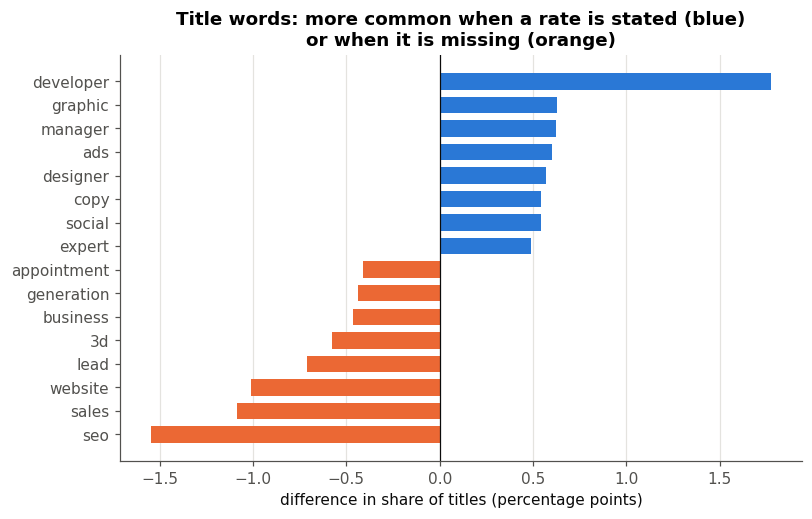

Largest difference for any common word: 1.8 percentage points


In [15]:
def title_share(frame):
    shares = {}
    for title_key in frame["title_key"].dropna():
        for word in set(tokenize(title_key)):
            shares[word] = shares.get(word, 0) + 1
    return pd.Series(shares) / len(frame) * 100

states = title_share(hourly_jobs[hourly_jobs["rate_group"] == "states rate"])
missing = title_share(hourly_jobs[hourly_jobs["rate_group"] == "no/partial rate"])
word_totals = pd.Series(count_ngrams(hourly_jobs["title_key"].dropna().map(lambda t: " ".join(set(tokenize(t)))), 1))
common_words = word_totals[word_totals >= 500].index
word_diff = pd.DataFrame({"states_rate_pct": states.reindex(common_words).fillna(0),
                          "no_rate_pct": missing.reindex(common_words).fillna(0)})
word_diff["difference_pp"] = word_diff["states_rate_pct"] - word_diff["no_rate_pct"]
word_diff = word_diff.sort_values("difference_pp")
extremes = pd.concat([word_diff.head(8), word_diff.tail(8)])

fig, ax = plt.subplots(figsize=(8, 4.8))
colors = [ORANGE if v < 0 else BLUE for v in extremes["difference_pp"]]
ax.barh(extremes.index, extremes["difference_pp"], color=colors, height=0.7)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("difference in share of titles (percentage points)")
ax.set_title("Title words: more common when a rate is stated (blue)\nor when it is missing (orange)")
ax.grid(axis="y", visible=False)
plt.show()
largest_word_gap = word_diff["difference_pp"].abs().max()
print(f"Largest difference for any common word: {largest_word_gap:.1f} percentage points")

**Finding** → The two groups are **very similar**. Cramér's V is about 0.07 for country and close to 0 for weekday, both negligible, and median title length differs by one word at most. There is a mild, consistent tilt: jobs from the US and the UK state a rate slightly more often, and jobs from India, the UAE and the Netherlands slightly less often; "developer" titles state a rate more often, while SEO, sales and lead-generation titles leave it out more often. No common word differs by more than about 2 percentage points.

**Evidence** → The Cramér's V values, the country table and the word chart.

**What a later notebook must test** → On the features checked here (country, weekday, title length and common title words), hourly jobs with a complete stated rate look similar to other hourly jobs, with a small country and title-word tilt. Job categories are not checked yet: NB04 repeats this comparison by category. Task 1 describes jobs that state a complete rate, not every hourly job, and names the tilt (US and developer roles over-represented; sales, SEO and lead generation under-represented) as a limitation.

## 5. First look at title words

A preview for Notebook 03, which builds job categories. Words come from `title_key` (cleaned, lower-case title). **Stop words** are filler words such as "for", "the", "need", removed so that meaningful words stand out (list in decision D-024). **Two-word phrases** (bigrams) are pairs of neighbouring words; a pair is only counted if neither word is a stop word, so no phrase is invented across a removed word.

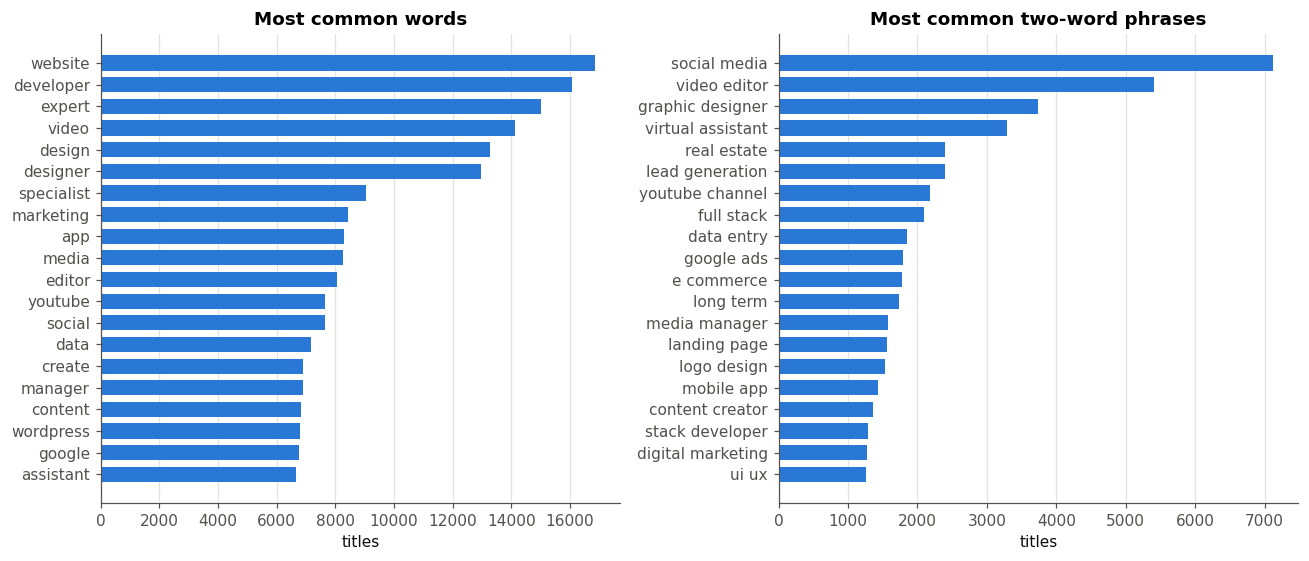

Distinct words: 39,233. The 233 most common words make up half of all word occurrences; 1,438 words make up 80%.
Stop words removed: a, an, and, are, at, be, by, for, from, i, in, is, looking, my, need, needed, of, on, or, our, the, this, to, we, with, you, your


In [16]:
top_words = top_ngrams(text_jobs["title_key"], n=1, k=20)
top_bigrams = top_ngrams(text_jobs["title_key"], n=2, k=20)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, table, title in [(axes[0], top_words, "Most common words"), (axes[1], top_bigrams, "Most common two-word phrases")]:
    part = table[::-1]
    ax.barh(part["term"], part["count"], color=BLUE, height=0.7)
    ax.set_title(title)
    ax.set_xlabel("titles")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

word_counts = pd.Series(count_ngrams(text_jobs["title_key"], 1)).sort_values(ascending=False)
coverage = word_counts.cumsum() / word_counts.sum()
words_for_50 = int((coverage < 0.50).sum() + 1)
words_for_80 = int((coverage < 0.80).sum() + 1)
print(f"Distinct words: {len(word_counts):,}. The {words_for_50} most common words make up half of all "
      f"word occurrences; {words_for_80:,} words make up 80%.")
print("Stop words removed:", ", ".join(sorted(STOP_WORDS)))

**Finding** → Demand is visible directly in the phrases: social media, video editing, graphic design, virtual assistants, real estate, lead generation, YouTube, full-stack development, data entry, Google Ads, e-commerce, landing pages and logo design. Vocabulary is very concentrated: a couple of hundred words make up half of all word occurrences, out of about 39,000 distinct words.

One limitation is visible: hyphens and most symbols disappear in `title_key`, so "e-commerce" becomes "e commerce" (a `+` or `#` attached to a word stays, so "C++" and "C#" remain distinct words). Words such as "expert", "specialist" and "long term" describe the job, not the field.

**Evidence** → The two charts and the coverage numbers.

**What a later notebook must test** → NB03 must handle technical tokens (C++, .NET, e-commerce) before building categories, and must separate field words (designer, developer) from descriptor words (expert, long term).

## 6. Sensitivity checks: matched to each kind of result

A **sensitivity check** repeats a result after changing one reasonable choice, to see whether the conclusion holds (decision D-022). Each risk is checked only where it matters:

| Result type | Risk | Check |
|---|---|---|
| pay | extreme values | without flagged extreme pay |
| title demand | possible reposts double-counting | without `possible_repost_3d` |
| time patterns | days with a collection gap | without the three intraday-gap days |

**Spearman rank correlation** compares two rankings: 1 means the same order, 0 means unrelated.

In [17]:
# Pay: country medians with and without extreme values.
no_extreme = hourly_pay[~hourly_pay["extreme_hourly_rate_flag"]]
median_without = no_extreme.groupby("country", observed=True)["hourly_mid"].median().reindex(hourly_country.index)
pay_rank_rho = spearmanr(hourly_country["median"], median_without).statistic
countries_changed = int((hourly_country["median"] != median_without).sum())

# Title demand: top-20 phrases with and without possible reposts.
bigrams_all = pd.Series(count_ngrams(text_jobs["title_key"], 2)).sort_values(ascending=False).head(20)
bigrams_no_repost = pd.Series(count_ngrams(text_jobs.loc[~text_jobs["possible_repost_3d"], "title_key"], 2)) \
    .sort_values(ascending=False).head(20)
shared_phrases = bigrams_all.index.intersection(bigrams_no_repost.index)
phrase_rank_rho = spearmanr(bigrams_all.rank()[shared_phrases], bigrams_no_repost.rank()[shared_phrases]).statistic

# Time: weekday shares (per day) with and without intraday-gap days.
no_gap = time_jobs[time_jobs["day_status"] != "intraday_gap"]
days_no_gap = no_gap.groupby("posted_date", observed=True)["weekday"].first().value_counts().reindex(WEEKDAYS)
share_all = per_weekday / per_weekday.sum() * 100
share_no_gap = (no_gap["weekday"].value_counts().reindex(WEEKDAYS) / days_no_gap)
share_no_gap = share_no_gap / share_no_gap.sum() * 100
weekday_shift = (share_all - share_no_gap).abs().max()

sensitivity = pd.DataFrame([
    {"result": "hourly rate by country", "check": "without extreme pay",
     "measure": "rank correlation of country medians", "value": round(pay_rank_rho, 3),
     "detail": f"{countries_changed} of {len(hourly_country)} country medians change at all"},
    {"result": "top 20 two-word phrases", "check": "without possible reposts",
     "measure": "phrases still in the top 20", "value": len(shared_phrases),
     "detail": f"rank correlation {phrase_rank_rho:.3f}; {int(text_jobs['possible_repost_3d'].sum()):,} rows removed"},
    {"result": "weekday pattern", "check": "without intraday-gap days",
     "measure": "largest change in a weekday's share (pp)", "value": round(weekday_shift, 2),
     "detail": "shares of average postings per day"},
])
sensitivity

,result,check,measure,value,detail
0,hourly rate by country,without extreme pay,rank correlation of country medians,0.99,8 of 91 country medians change at all
1,top 20 two-word phrases,without possible reposts,phrases still in the top 20,20.00,"rank correlation 0.985; 9,190 rows removed"
2,weekday pattern,without intraday-gap days,largest change in a weekday's share (pp),0.16,shares of average postings per day


**Finding** → All three conclusions hold. Country pay rankings are almost identical without extreme values (rank correlation about 0.99). The top 20 phrases are the same 20 without possible reposts, in nearly the same order. Weekday shares move by less than a quarter of a percentage point without the gap days.

**Evidence** → The sensitivity table.

**What a later notebook must test** → Later notebooks repeat the matching check for their own results, because a check that is harmless here (for example reposts on the top 20 phrases) may matter for a smaller category or a single day.

## 7. Hypotheses for later notebooks

Each hypothesis comes from a finding above and is tested later.

| # | Hypothesis | Evidence in this notebook | Tested in |
|---|---|---|---|
| H1 | A few dozen job categories (design, video, marketing, development, data, admin) cover most demand | concentrated vocabulary and phrases (section 5) | NB03 |
| H2 | Title words explain part, but only part, of pay; country and category also matter | wide, overlapping pay ranges (sections 2.1, 3.1) | NB04 (Task 1) |
| H3 | Country differences in hourly rate remain after accounting for job category | country medians from about $13 to $25 (section 3.1) | NB04 (Task 4) |
| H4 | Hourly jobs that state a rate represent hourly jobs fairly, with a mild tilt toward US and developer jobs | Cramér's V below 0.1 (section 4) | NB04 (limitation of Task 1) |
| H5 | Daily demand has a stable weekly cycle (weekdays high, weekends low) that a forecast must include | averages per weekday (section 2.3) | NB06 (Tasks 3 and 8) |
| H6 | Category demand rankings are stable to possible reposts, but small or fast-growing categories may not be | sensitivity table (section 6) | NB05 (Task 2) |
| H7 | Contract type and country carry information beyond the title and are useful recommendation filters | contract mix by country (section 3.3) | NB07 (Task 5) |

## 8. Claims check and summary

Every number quoted in this notebook's text is checked here against the data, so the words cannot drift away from the results.

In [18]:
us_share = 100 * country_counts.get("United States", 0) / known
hourly_med = hourly_country["median"]
claims = {
    "~58% hourly, ~42% fixed-price": round(100 * jobs.loc[valid, "contract_type"].eq("hourly").mean()) == 58,
    "more than a quarter of hourly jobs state no rate":
        (jobs.loc[valid, "pay_info"].eq("hourly_no_rate").sum() / jobs.loc[valid, "contract_type"].eq("hourly").sum()) > 0.25,
    "hourly median $22.50, IQR $14-$35": (hourly_pay["hourly_mid"].median() == 22.5
                                         and hourly_pay["hourly_mid"].quantile(0.25) == 14
                                         and hourly_pay["hourly_mid"].quantile(0.75) == 35),
    "budget median $100, IQR $25-$300": (budget_pay["budget"].median() == 100
                                        and budget_pay["budget"].quantile(0.25) == 25
                                        and budget_pay["budget"].quantile(0.75) == 300),
    "budget mean about 9x median": 8.5 <= budget_pay["budget"].mean() / budget_pay["budget"].median() <= 9.5,
    "medians and IQRs unchanged without extremes": (
        hourly_summary.loc["without flagged extremes", ["median", "p25", "p75"]].tolist()
        == hourly_summary.loc["all eligible jobs", ["median", "p25", "p75"]].tolist()
        and budget_summary.loc["without flagged extremes", ["median", "p25", "p75"]].tolist()
        == budget_summary.loc["all eligible jobs", ["median", "p25", "p75"]].tolist()),
    "US about 42% of jobs with a country": round(us_share) == 42,
    "top 10 about three quarters": 72 <= top10_share <= 78,
    "212 countries, almost half below 30 jobs": country_counts.size == 212 and 0.4 <= small_countries / 212 <= 0.5,
    "6 Fridays and Saturdays, 5 of other weekdays": (days_per_weekday[["Friday", "Saturday"]] == 6).all()
                                                    and (days_per_weekday.drop(["Friday", "Saturday"]) == 5).all(),
    "Mon-Thu 6,800-7,100 per day": per_weekday[["Monday", "Tuesday", "Wednesday", "Thursday"]].between(6800, 7100).all(),
    "Friday about 6,500 and below Mon-Thu": 6400 <= per_weekday["Friday"] < per_weekday[["Monday", "Tuesday", "Wednesday", "Thursday"]].min(),
    "weekend 4,400-4,800 per day": per_weekday[["Saturday", "Sunday"]].between(4400, 4800).all(),
    "raw totals would make Friday busiest": time_jobs["weekday"].value_counts().idxmax() == "Friday",
    "peak around 17 UTC, low around 05 UTC": per_hour.idxmax() in (16, 17, 18) and per_hour.idxmin() in (4, 5, 6),
    "half of titles 6 words or fewer": text_jobs["title_word_count"].median() <= 6,
    "more than 99.9% Latin script": (text_jobs["title_script"] == "latin").mean() > 0.999,
    "large-market hourly medians from $13 (Philippines) to $25 (US)": (
        hourly_med["Philippines"] == 13 and hourly_med["United States"] == 25
        and hourly_country.sort_values("jobs", ascending=False).head(20)["median"].between(13, 25).all()),
    "UK/CA/AU/IE/NZ/DE/FR/ES/IT/NL hourly medians $20-$24": hourly_med[["United Kingdom", "Canada", "Australia", "Ireland",
        "New Zealand", "Germany", "France", "Spain", "Italy", "Netherlands"]].between(20, 24).all(),
    "budgets: India $70, Pakistan $40, China $30": (budget_country.loc[["India", "Pakistan", "China"], "median"].tolist()
                                                     == [70, 40, 30]),
    "US/UK/AU/CA budgets $95-$100": budget_country.loc[["United States", "United Kingdom", "Australia", "Canada"],
                                                        "median"].between(95, 100).all(),
    "India and Pakistan mostly fixed-price (57-61%)": contract_mix.loc[["India", "Pakistan"], "fixed"].between(57, 61.5).all(),
    "US/UK/CA/AU mostly hourly (55-65%)": contract_mix.loc[["United States", "United Kingdom", "Canada", "Australia"],
                                                           "hourly"].between(55, 65.5).all(),
    "Cramér's V country about 0.07 (< 0.1)": 0.05 <= v_country < 0.1,
    "Cramér's V weekday close to 0 (< 0.02)": v_weekday < 0.02,
    "title length differs by at most one word": abs(length["states rate"] - length["no/partial rate"]) <= 1,
    "no common word differs by more than about 2 pp": largest_word_gap < 2.0,
    "US states rate more often; India less often": (country_shares.loc["United States", "difference_pp"] > 0
                                                    and country_shares.loc["India", "difference_pp"] < 0),
    "developer more often with rate; seo/sales less often": (word_diff.loc["developer", "difference_pp"] > 0
                                                             and word_diff.loc[["seo", "sales"], "difference_pp"].lt(0).all()),
    "about 39,000 distinct words; a couple of hundred cover half": 38_000 <= len(word_counts) <= 40_000 and words_for_50 <= 300,
    "country pay ranking rho about 0.99": pay_rank_rho >= 0.98,
    "same 20 phrases without possible reposts": len(shared_phrases) == 20,
    "weekday shares move less than 0.25 pp": weekday_shift < 0.25,
}
claims = pd.Series(claims, name="true").to_frame()
assert claims["true"].all(), claims[~claims["true"]]
claims

,true
"~58% hourly, ~42% fixed-price",True
more than a quarter of hourly jobs state no rate,True
"hourly median $22.50, IQR $14-$35",True
"budget median $100, IQR $25-$300",True
budget mean about 9x median,True
medians and IQRs unchanged without extremes,True
US about 42% of jobs with a country,True
top 10 about three quarters,True
"212 countries, almost half below 30 jobs",True
"6 Fridays and Saturdays, 5 of other weekdays",True


**Summary**

- **Pay** has a typical value of $22.50 per hour or $100 per fixed-price job, with long tails. Medians are stable; means are not.
- **Geography** is concentrated (US about 42%) and shapes both pay level and contract type; small countries need caution.
- **Timing** follows a clear weekly cycle; daily comparisons must use averages per day because the window has unequal weekday counts.
- **Jobs that state a complete hourly rate** look similar to other hourly jobs on country, weekday, title length and title words, with a small tilt; job categories are checked in NB04.
- **Titles** are short and concentrated; a few hundred words carry most of the meaning, and technical tokens need care.
- All three sensitivity checks leave the conclusions unchanged.

These findings are the starting point for Notebook 03 (job categories) and the hypotheses H1-H7 above.